# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn
- Matplotlib


In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [18]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/adviseinvest_historical_data.csv')

# 1. Preview the dataframe structure
print("--- FIRST 5 ROWS ---")
display(df.head())

# 2. Basic dataset info (data types, non-null counts)
print("\n--- DATASET INFO ---")
df.info()

# 3. Descriptive statistics (for numeric columns to spot potential outliers)
print("\n--- DESCRIPTIVE STATISTICS ---")
display(df.describe())

# 4. Check for missing values
print("\n--- MISSING VALUES PER COLUMN ---")
print(df.isnull().sum())

# 5. Check for duplicate records
print("\n--- NUMBER OF DUPLICATE ROWS ---")
print(df.duplicated().sum())


--- FIRST 5 ROWS ---


,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0



--- DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB

--- DESCRIPTIVE STATISTICS ---


,customer_id,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
mean,14850.475563,0.546638,33766.893303,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,29602.000000,1.000000,159450.000000,132.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000



--- MISSING VALUES PER COLUMN ---
customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64

--- NUMBER OF DUPLICATE ROWS ---
3


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. The only column with any missing values is new_car with 2 missing values. There are 3 duplicate rows.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [19]:
# 2.1: Duplicate removal
df_clean = df.drop_duplicates().copy()

# 2.2: Outlier detection & removal
# Income has negative values (e.g., -65600) which is an outlier/data entry error. We will filter out negative income.
df_clean = df_clean[df_clean['income'] >= 0]

# 2.3: Handle missing data
# There are 2 missing values in 'new_car'. We will impute these with the mode (most common value).
new_car_mode = df_clean['new_car'].mode()[0]
df_clean['new_car'] = df_clean['new_car'].fillna(new_car_mode)

# 2.4: Remove variables that are not helpful or only available after the call has answered
# 'customer_id' is just an identifier.
# 'product' is determined after the customer has answered, so it is a leakage variable and useless for prediction.
columns_to_drop = ['customer_id', 'product']
df_clean = df_clean.drop(columns=columns_to_drop)

# Show cleaning results
print(f"Original rows: {len(df)}")
print(f"Cleaned rows: {len(df_clean)}")
print(f"Remaining columns: {list(df_clean.columns)}")
print(f"Remaining missing values:\n{df_clean.isnull().sum()}")


Original rows: 29504
Cleaned rows: 29499
Remaining columns: ['answered', 'income', 'female', 'age', 'job', 'num_dependents', 'rent', 'own_res', 'new_car', 'chk_acct', 'sav_acct', 'num_accts', 'mobile']
Remaining missing values:
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           0
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
dtype: int64


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 It was indentified that the income column had negative values, which is impossible for household or individual income to be in the negatives. Any rows where income was negative were filtered out. Getting ride of these rows prevents them from skewing the data. New_car also had missing entries, they were replaced with the mode.

2.6 The columns customer_id and product from the set. Customer_id has no use for predicitive capability. Product shows when something was purchased after the call was answered, therefore has no predictability of whether customers will answer calls or not.


## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [20]:
# 2.2 Standardize variables

# Change 'answered' to boolean type
df_clean['answered'] = df_clean['answered'].astype(bool)

# Convert other columns that should be integers to integer type
# 'new_car' is float64 due to handling missing values; we cast it to int64.
df_clean['new_car'] = df_clean['new_car'].astype(int)

# Verify types
print(df_clean.dtypes)


answered            bool
income             int64
female            object
age                int64
job                int64
num_dependents     int64
rent               int64
own_res            int64
new_car            int64
chk_acct           int64
sav_acct           int64
num_accts          int64
mobile             int64
dtype: object


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [21]:
# 2.3 Convert variables to categorical

# Converting appropriate columns to categorical types
columns_to_categorical = ['female', 'job', 'chk_acct', 'sav_acct']

for col in columns_to_categorical:
    df_clean[col] = df_clean[col].astype('category')

# Verify the conversions
print(df_clean[columns_to_categorical].dtypes)


female      category
job         category
chk_acct    category
sav_acct    category
dtype: object


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



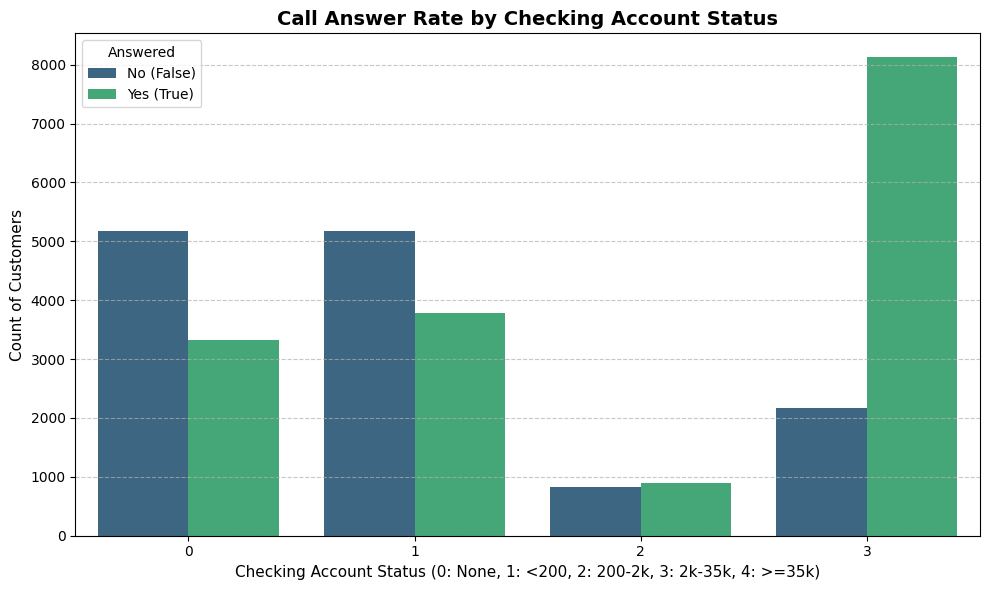

In [22]:
# Chart 3.1: Relationship between Checking Account Status and Answered Status
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.countplot(data=df_clean, x='chk_acct', hue='answered', palette='viridis')

plt.title('Call Answer Rate by Checking Account Status', fontsize=14, fontweight='bold')
plt.xlabel('Checking Account Status (0: None, 1: <200, 2: 200-2k, 3: 2k-35k, 4: >=35k)', fontsize=11)
plt.ylabel('Count of Customers', fontsize=11)
plt.legend(title='Answered', labels=['No (False)', 'Yes (True)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


/tmp/ipykernel_565/1389381688.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='answered', y='income', palette='coolwarm')


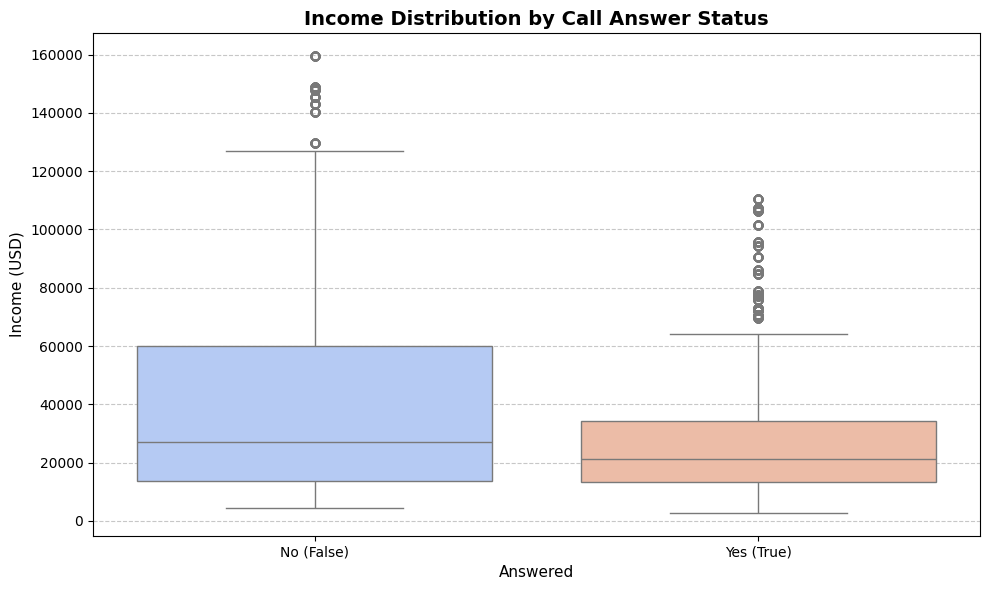

In [23]:
# Chart 3.2: Relationship between Customer Income and Answered Status
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x='answered', y='income', palette='coolwarm')

plt.title('Income Distribution by Call Answer Status', fontsize=14, fontweight='bold')
plt.xlabel('Answered', fontsize=11)
plt.ylabel('Income (USD)', fontsize=11)
plt.xticks([0, 1], ['No (False)', 'Yes (True)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


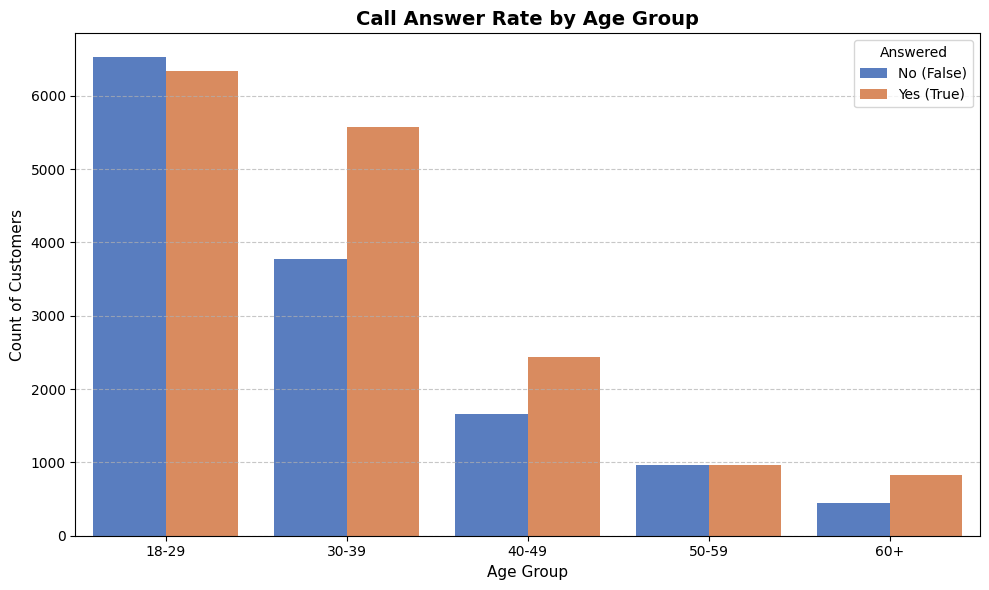

In [24]:
# Chart 3.3: Relationship between Age Groups and Answered Status
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Create age bins for cleaner visualization
df_temp = df_clean.copy()
df_temp['age_group'] = pd.cut(df_temp['age'], bins=[18, 30, 40, 50, 60, 100], labels=['18-29', '30-39', '40-49', '50-59', '60+'])

plt.figure(figsize=(10, 6))
sns.countplot(data=df_temp, x='age_group', hue='answered', palette='muted')

plt.title('Call Answer Rate by Age Group', fontsize=14, fontweight='bold')
plt.xlabel('Age Group', fontsize=11)
plt.ylabel('Count of Customers', fontsize=11)
plt.legend(title='Answered', labels=['No (False)', 'Yes (True)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


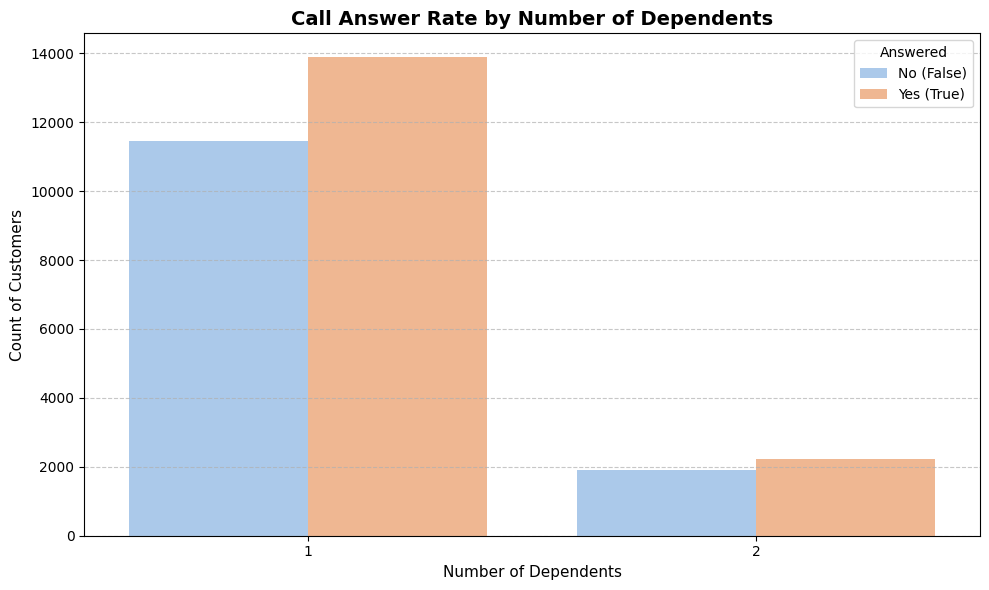

In [25]:
# Chart 3.4: Relationship between Number of Dependents and Answered Status
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.countplot(data=df_clean, x='num_dependents', hue='answered', palette='pastel')

plt.title('Call Answer Rate by Number of Dependents', fontsize=14, fontweight='bold')
plt.xlabel('Number of Dependents', fontsize=11)
plt.ylabel('Count of Customers', fontsize=11)
plt.legend(title='Answered', labels=['No (False)', 'Yes (True)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


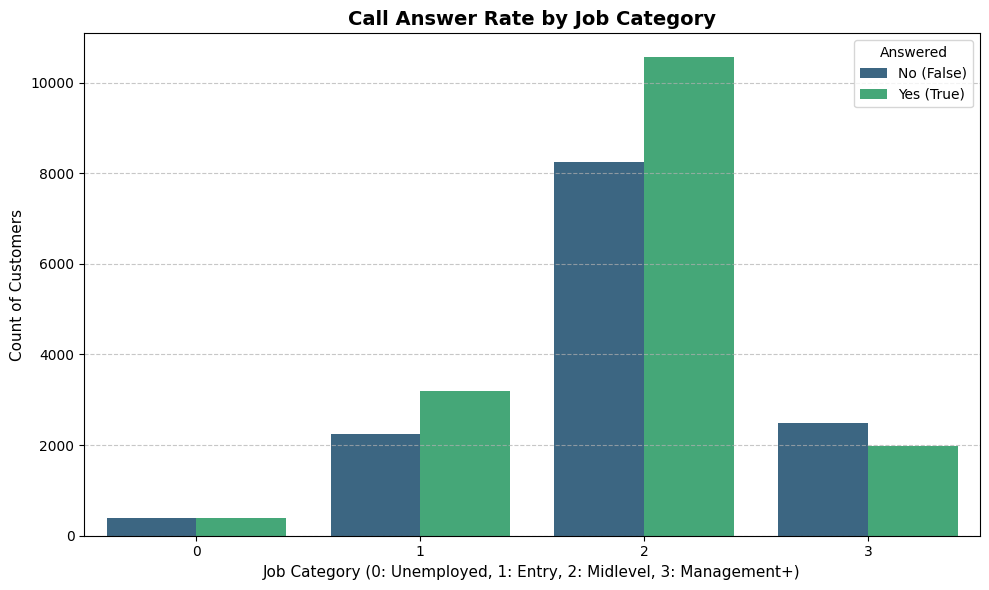

In [26]:
# Chart 3.5: Call Answer Rate by Job Category
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.countplot(data=df_clean, x='job', hue='answered', palette='viridis')

plt.title('Call Answer Rate by Job Category', fontsize=14, fontweight='bold')
plt.xlabel('Job Category (0: Unemployed, 1: Entry, 2: Midlevel, 3: Management+)', fontsize=11)
plt.ylabel('Count of Customers', fontsize=11)
plt.legend(title='Answered', labels=['No (False)', 'Yes (True)'])
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Age group seems to have a significant relationship with the target variable. It shows that the youngest age group has the highest false rate, higher than the true rate in its own group. As the age groups increase, there are less unanswered calls and answered calls, but unanswered calls decreases much more.

3.7. Num_dependents had a weak relationship. This variable has no predictive power or relationship with the target variable. Job is another variable with a weaker relationship, the proportion of customers answering vs not answering is very similar between job categories. These don't need to be removed, as the decision tree will prioritize stronger predictors and will ignore the weaker ones.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [27]:
# 4.1 Calculate the base probability of answering
base_prob = df_clean['answered'].mean()
print(f"Base probability of a customer answering the call: {base_prob:.4f} ({base_prob * 100:.2f}%)")

Base probability of a customer answering the call: 0.5467 (54.67%)


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [28]:
from sklearn.model_selection import train_test_split

# Define feature matrix X and target vector y
X = df_clean.drop(columns=['answered'])
y = df_clean['answered']

# Split into training and testing sets (using an 80/20 split and a fixed random state for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Print dataset shapes to verify the split
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (23599, 12)
X_test shape: (5900, 12)
y_train shape: (23599,)
y_test shape: (5900,)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

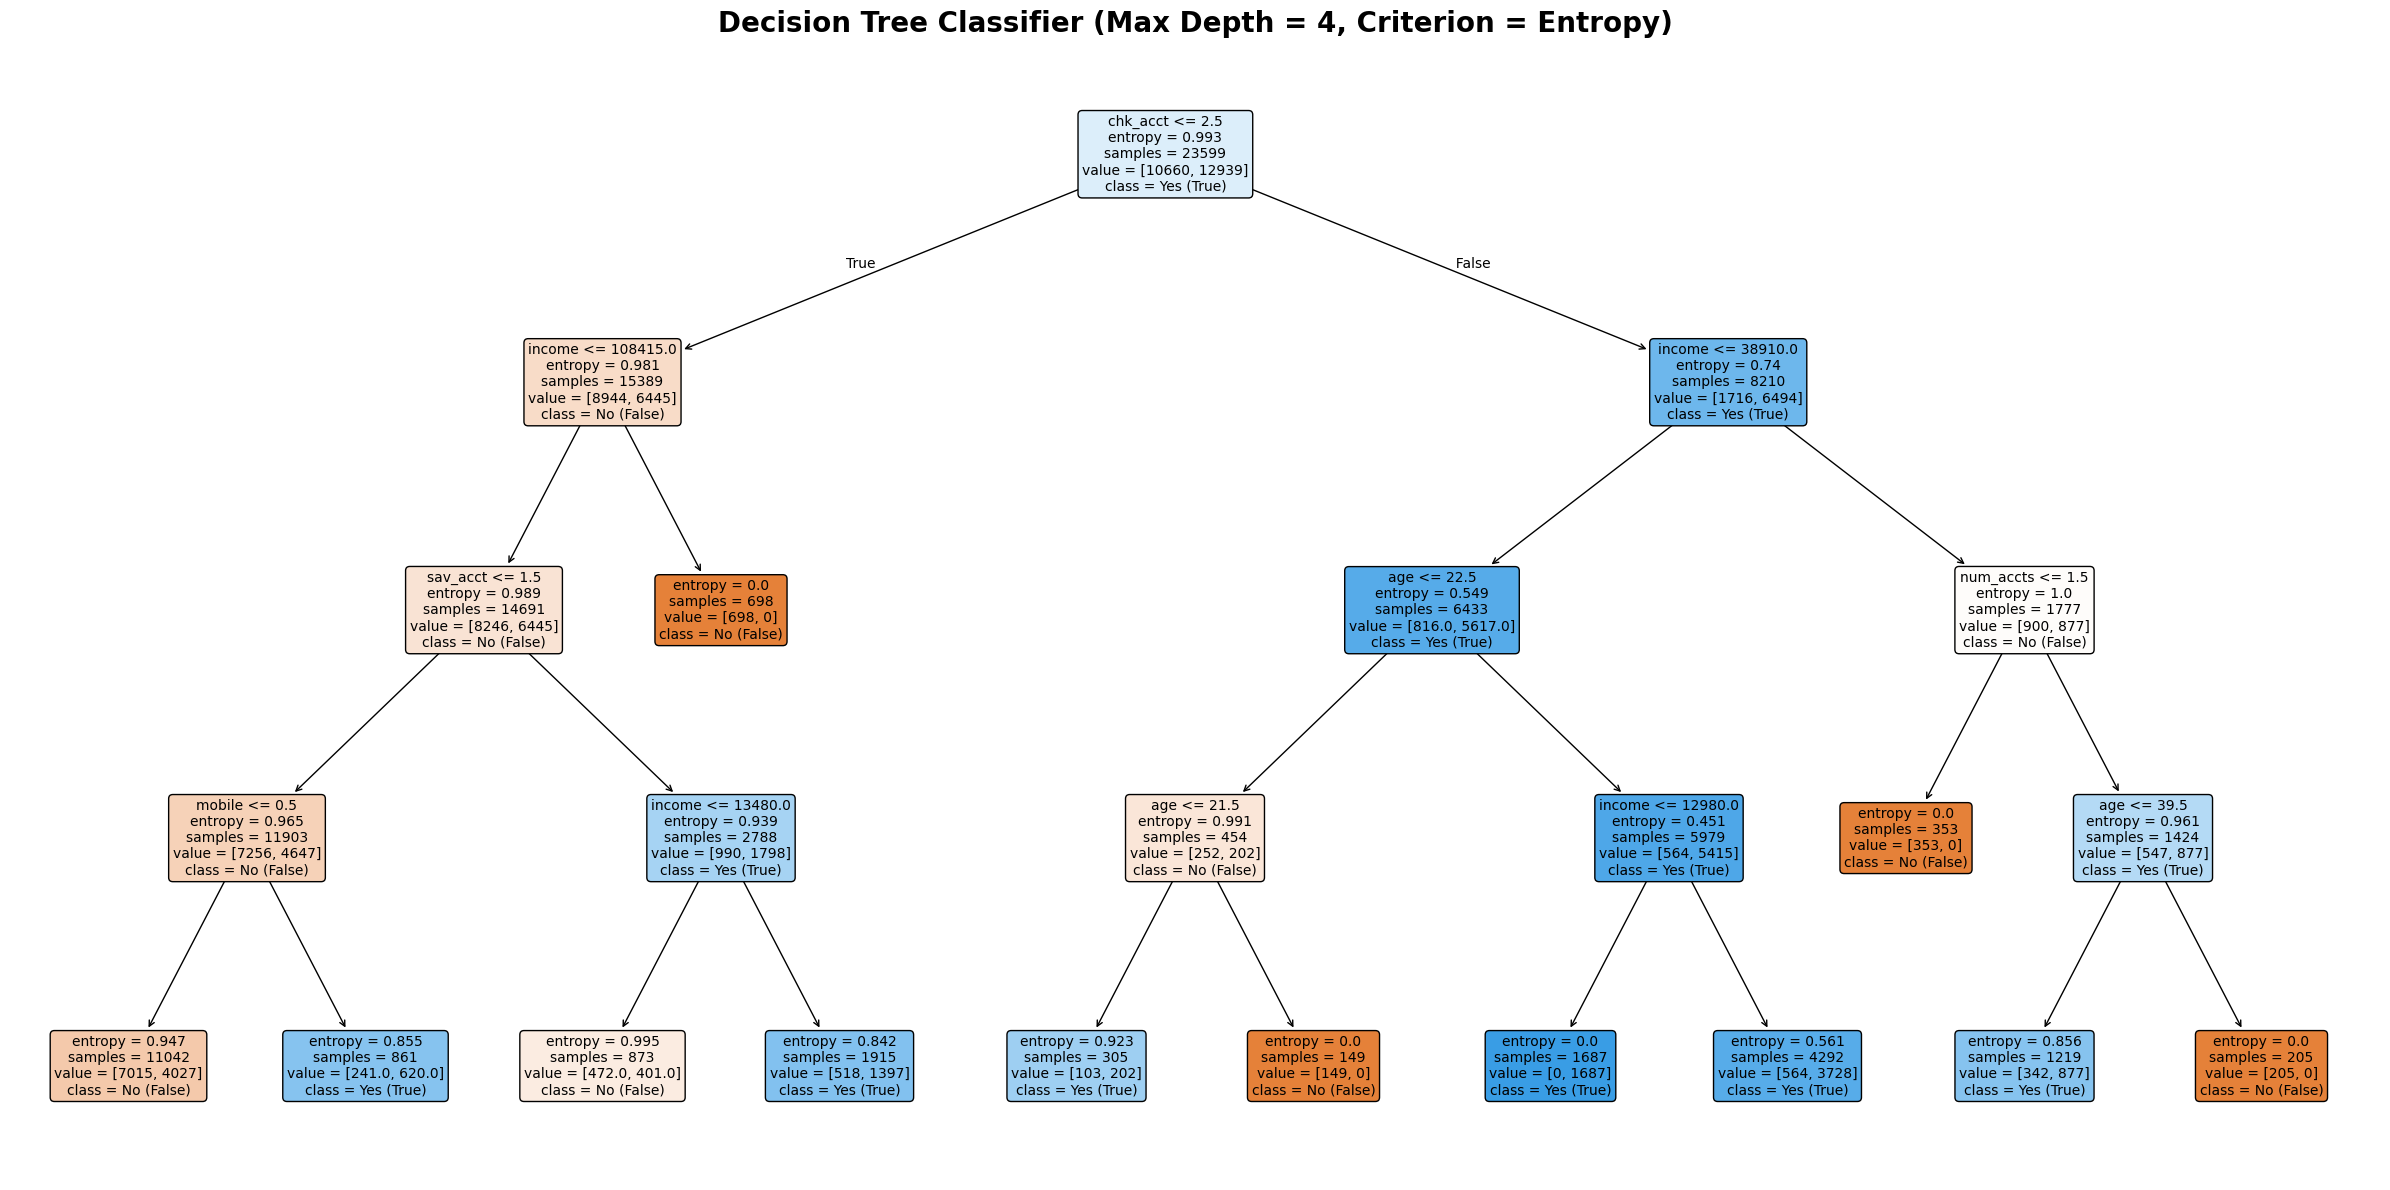

In [29]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Initialize the Decision Tree Classifier with entropy and max depth of 4
clf = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

# Train the model on the training data
clf.fit(X_train, y_train)

# Set up the visualization figure size
plt.figure(figsize=(24, 12))

# Plot the decision tree
plot_tree(
    clf,
    feature_names=X.columns.tolist(),
    class_names=['No (False)', 'Yes (True)'],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title('Decision Tree Classifier (Max Depth = 4, Criterion = Entropy)', fontsize=20, fontweight='bold')
plt.tight_layout()
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [31]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# 1. One-hot encode categorical features so there are no raw string values (like 'M')
X_encoded = pd.get_dummies(X, columns=['female', 'job', 'chk_acct', 'sav_acct'], drop_first=True)

# 2. Re-split the encoded dataset into train and test sets
X_train_enc, X_test_enc, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# 3. Re-initialize and retrain the model on numeric-only data
clf_encoded = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
clf_encoded.fit(X_train_enc, y_train)

# 4. Calculate and print the new accuracy
tree_accuracy = clf_encoded.score(X_test_enc, y_test)
print(f"Decision Tree Model Accuracy: {tree_accuracy:.4f} ({tree_accuracy * 100:.2f}%)")
print(f"Baseline Probability: {base_prob:.4f} ({base_prob * 100:.2f}%)")

Decision Tree Model Accuracy: 0.7144 (71.44%)
Baseline Probability: 0.5467 (54.67%)


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. There is a much higher probability of 71% in comparison to the 54%.

2. This difference increases efficiency by almost 17%. This allows for managers to target responsive leads, increasing the ratio of answered to unanswered calls.


### 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

Confusion Matrix:
[[2351  361]
 [1324 1864]]

True Negatives (TN): 2351
False Positives (FP): 361
False Negatives (FN): 1324
True Positives (TP): 1864


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

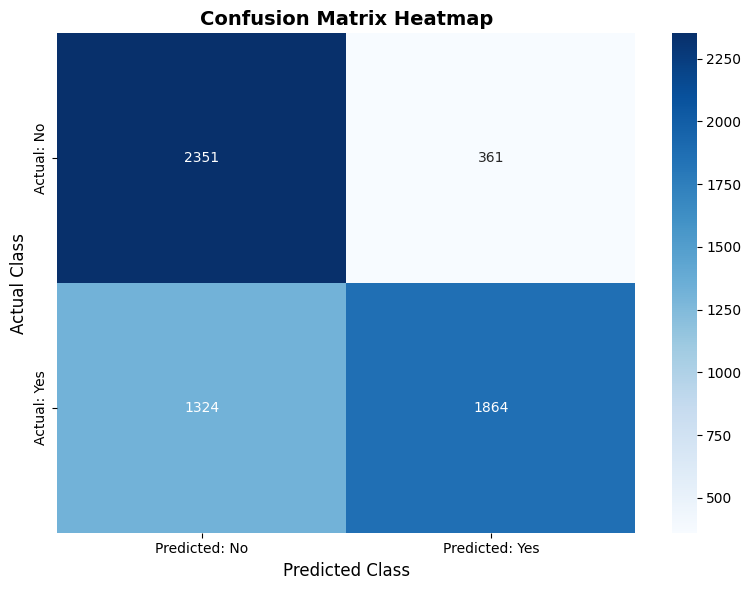

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

True Positives (TP): 1864
False Positives (FP): 361
Revenue from True Positives: $139,800
Cost of False Positives: $9,025
Net Profit using the Model: $130,775


### 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

Total Customers in Test Set: 5900
Actual Answered (Positive): 3188
Actual Unanswered (Negative): 2712
Revenue from Answered Calls: $239,100
Cost of Unanswered Calls: $67,800
Net Profit without Model (Call Everyone): $171,300


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The net profit without the model is $41k more than the net profit with the model. The revenue is much higher and the cost is much higher than with the model.

2. With the predictive model they would be making a lot less money, but would be less underutilized and getting unanswered calls.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

Tuned Decision Tree Model Accuracy: 0.7634 (76.34%)
Original Decision Tree Accuracy: 0.7144 (71.44%)


### 5.4 Apply the Model to New Customers

### Do the Following
- Import the "adviseinvest_new_customer_data.csv" file
- Copy and past the data cleanup steps from 2.1 and 2.2
- Using the tree model that you created in step 5.3, predict each customer for the target variable by feeding the new customer data into the model
- Predict the number of customers who will be yes/no for the target variable

--- NEW CUSTOMER PREDICTIONS SUMMARY ---
predicted_answered
False    633
True     367
Name: count, dtype: int64


# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 No we did not. Based on our calculations, without the model we had a gross revenue of $239,100, which was higher than with the model. Calling everyone requires many more calls than the model, it does show a mass reduction in staff labor hours, reducing the underutilization issue.

6.2 The business could utilize the model for staffing optimization, with predictive scheduling, employees will have specific times for the calls, this will keep representatives occupied at all times.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"